In [1]:
import yaml
import pandas as pd
import glob
from pathlib import Path
import json
import os
import sys
sys.path.append("..")

import wandb
api = wandb.Api()

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


In [2]:
root_sweeps = Path("../../wandb-sweep-data-qnrl/")
root_sweeps.mkdir(parents=True, exist_ok=True)

In [3]:
project_id = "qnrl"

In [4]:
# sweeps = api.project(project_id).sweeps()

In [5]:
# [dict(name=s.name, id=s.id) for s in sweeps]

In [6]:
# List of sweep names and their IDs for reference.
sweep_name_id = { # name: id
    # QnRL.
    'qnrl/FrozenLake-v1': 'sgi6zb0t',
    'qnrl/CliffWalking-v1': 'h4g5er22',
    'qnrl/Acrobot-v1': 'sd4va92r',
    'qnrl/CartPole-v1': '4ykq4hvw',
    
    # C51.
    'c51/FrozenLake-v1': '3exa9jvo',
    'c51/CliffWalking-v1': '1nlfftsy',
    'c51/Acrobot-v1': 's3xwn85k',
    'c51/CartPole-v1': '7raha9om',
}

# Best runs tagged for each sweep.
# Retrieve via the code:
#    {sweep_name: [run.id for run in api.sweep(f"{project_id}/{sweep_id}").runs if "best-seed-group" in run.tags] for sweep_name, sweep_id in sweep_name_id.items()}
best_runs_for_sweep = { # name: [id]
    # QnRL.
    "qnrl/FrozenLake-v1": ["asqt9rhf", "pfhzc37a", "tcmzk822", "o8bvmgah"],
    "qnrl/CliffWalking-v1": ["gg17kbpu", "3vn1egt0", "j9n68hn4", "au4el5rn"],
    "qnrl/Acrobot-v1": ["5m2sdda0", "oehcc3xd", "40j6hb1a", "l1c029ff"],
    "qnrl/CartPole-v1": ["atroi3e3", "ridysmu3", "z5elw4vo", "inwzalpf"],
    
    # C51.
    "c51/FrozenLake-v1": ["3dow3k33", "69lp8uef", "ard9oh61", "6ozx435e"],
    "c51/CliffWalking-v1": ["5ti67g7h", "gbkzvg60", "bgrjs1z8", "nk5iyhn3"],
    "c51/Acrobot-v1": ["5tai0d5b", "57wv5oow", "nqtj0noh", "6xnb70dg"],
    "c51/CartPole-v1": ["e0x5vmzu", "xxcaueu9", "jit954em", "x0tak5kj"]
}

In [7]:
# import numpy as np
# df = pd.DataFrame([{'a':1.1, 'b':2.2}, {'a':'Infinity'}, {'a': '-Infinity'}, {'a':'NaN', 'b': 'NaN'}])
# df = df.replace(['Infinity', '+Infinity'], np.inf).infer_objects(copy=False)
# df = df.replace('-Infinity', -np.inf).infer_objects(copy=False)
# df = df.replace('NaN', np.nan).infer_objects(copy=False)
# df

In [8]:
# pd.read_parquet("../../wandb-sweep-data-qnrl/sweep-sgi6zb0t/run-zxv75x9v/history/0000.parquet")['eval/episode_reward'].dropna()

In [9]:
import ast
from qnrl.serialization import hash_serializable_object
def get_run_config_dict_from_metadata(metadata_file: Path):
    """Compute run config hash from original run program command string."""
    # Load metadata as JSON dictionary.
    with open(str(metadata_file), 'r') as f:
        metadata = json.load(f)
    
    # Get config string from run program command arguments.
    # Format is: --config="{...}"
    cfg_str = metadata['args'][1].split("--config=")[1]
    # Convert this string to dictionary via literal evaluation.
    cfg_dict = ast.literal_eval(cfg_str)
    return cfg_dict

In [10]:
metadata_path_tree = {
    # Each sweep has a dictionary of runs.
    Path(sweep_dir).stem.split('sweep-')[1]: {
        # Each run has a metadata JSON file.
        Path(run_dir).stem.split('run-')[1]: glob.glob(str(Path(run_dir)/'wandb-metadata.json')) for run_dir in glob.glob(str(Path(sweep_dir)/'*'))
    } for sweep_dir in glob.glob(str(root_sweeps/'*'))
}

In [11]:
config_path_tree = {
    # Each sweep has a dictionary of runs.
    Path(sweep_dir).stem.split('sweep-')[1]: {
        # Each run has a config YAML file.
        Path(run_dir).stem.split('run-')[1]: glob.glob(str(Path(run_dir)/'config.yaml')) for run_dir in glob.glob(str(Path(sweep_dir)/'*'))
    } for sweep_dir in glob.glob(str(root_sweeps/'*'))
}

In [12]:
history_path_tree = {
    # Each sweep has a dictionary of runs.
    Path(sweep_dir).stem.split('sweep-')[1]: {
        # Each run has a list of parquet files.
        Path(run_dir).stem.split('run-')[1]: glob.glob(str(Path(run_dir)/'history'/'*.parquet')) for run_dir in glob.glob(str(Path(sweep_dir)/'*'))
    } for sweep_dir in glob.glob(str(root_sweeps/'*'))
}

In [13]:
from collections import defaultdict
def group_runs_by_seed_group_hash(config_run_tree):
    seedgroups_tree = defaultdict(list)
    for run_id, config_paths in config_run_tree.items():
        if config_paths:
            with open(str(config_paths[0]), 'r') as f:
                config = yaml.safe_load(f)
            seed_group_hash = config["seed_group_hash"]["value"]
            seedgroups_tree[seed_group_hash].append(run_id)
    return dict(seedgroups_tree) # Convert to regular dictionary.

seedgroups_tree = {sweep_id: group_runs_by_seed_group_hash(run_tree) for sweep_id, run_tree in config_path_tree.items()}

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.axes
import matplotlib.figure
import numpy as np
import pyarrow.parquet as pq


def axis_plot_baraggmean(ax: matplotlib.axes.Axes, plot_meta: dict) -> tuple[matplotlib.axes.Axes, dict]:
    bar_names = []
    bar_values = []
    bar_colors = []
    
    # Default colors to use for each series.
    cmap = plt.get_cmap()
    colors_idx = np.linspace(0, 1, len(plot_meta['series']))
    
    data = {}
    for i, series_meta in enumerate(plot_meta['series']):
        sweep_id = series_meta['sweep']
        run_ids = series_meta['runs']
        label = series_meta['label']
        color = series_meta.get('color', cmap(colors_idx[i]))
        
        key_y = series_meta['y']
        
        columns_to_read = [key_y]
        dfs = [
            # Each run can have multiple parquet files, so read them all in sequence and combine using `pd.concat()`.
            # Only read the x/y key columns from the file.
            # On the combined file: 
            # - set the index to the x-key
            # - drop rows where all elements are NaN
            # - sort by the x-key
            (
                pd.concat(
                    pd.read_parquet(parquet_file, columns=[key_y]) 
                    for parquet_file in history_path_tree[sweep_id][run_id]
                    if set(pq.read_schema(parquet_file).names).issuperset(set(columns_to_read))
                )
                .reset_index()
                .dropna(how='all')
                .sort_index()
            )
            for run_id in run_ids
        ]
        # Remove index entries that are `NaN`.
        dfs = [df[df.index.notna()] for df in dfs]
        

        # df = pd.concat({r: d[[key_y]].dropna(how="all").reset_index() for r,d in zip(run_ids, dfs)}, axis=1)
        df = pd.concat({r: d for r,d in zip(run_ids, dfs)}, axis=1, join='outer')
        df = df.dropna(how='all')
        # df.index = df.index.astype(int)
        df.columns = df.columns.reorder_levels([1, 0]) # make column indexing ["metric_key"]["run"]
        df = df.sort_index() # Combining train steps may leave DF not sorted, so sort by index to ensure monotonically increasing.
        
        # x = df.index
        bar_data = {
            'mean': (df[key_y].mean()).mean(),
            'min': (df[key_y].mean()).min(),
            'max': (df[key_y].mean()).max(),
            # 'std': (df[key_y].mean()).std(),
            'std': (df[key_y].std()).std(),
        }
        bar_names.append(label)
        bar_values.append(bar_data)
        bar_colors.append(color)
        
        data[label] = bar_data

    idx = list(range(len(bar_names)))
    
    # Label formatter string.
    label_fmt = plot_meta.get(
        'label-format', 
        "{key}",
        )
    labels = [label_fmt.format(key=key, **d) for key, d in data.items()]
    
    bar_orientation = plot_meta.get('bar-orientation', 'v') # 'v' or 'h'
    yerr_key = plot_meta.get('yerr', None) # mean, min, max, std.
    assert yerr_key is None or yerr_key in bar_values[0], f"Unsupported yerr key, must be either None or one of {list(bar_values[0].keys())}"
    bar_kwargs = dict(color=bar_colors, label=labels)
    if yerr_key is not None:
        bar_kwargs['yerr'] = [d[yerr_key] for d in bar_values]
    
    # Get which aggregation key to plot.
    agg_key = plot_meta.get('agg', 'mean') # mean, min, max, std.
    assert yerr_key is None or yerr_key in bar_values[0], f"Unsupported agg key, must be one of {list(bar_values[0].keys())}"
    values_to_plot = [d[agg_key] for d in bar_values]
    
    match bar_orientation:
        # Vertical bars.
        case 'v':
            # labels = [f"{key} ({d['mean']:.02f})" for key, d in data.items()]
            b = ax.bar(idx, values_to_plot, **bar_kwargs)
            xticks_kwargs = plot_meta.get('xticks', {})
            ax.set_xticks(idx, labels=bar_names, **xticks_kwargs)
        # Horizontal bars.
        case 'h':
            b = ax.barh(idx, values_to_plot, **bar_kwargs, color=bar_colors, label=labels)
            ax.set_yticks(idx, labels=bar_names)
            ax.invert_yaxis()
        case _:
            raise ValueError(f"Unsupported bar orientation '{bar_orientation}'")

    bar_label_kwargs = plot_meta.get('bar-label', None)
    assert isinstance(bar_label_kwargs, dict) or bar_label_kwargs is None, "bar label must be a dictionary or None"
    if bar_label_kwargs is not None:
        ax.bar_label(b, **bar_label_kwargs)
    
    # Return the modified axis and tracked data.
    return ax, data


def axis_plot_lineaggmean(ax: matplotlib.axes.Axes, plot_meta: dict) -> tuple[matplotlib.axes.Axes, dict]:
    
    # Default colors to use for each series.
    cmap = plt.get_cmap()
    colors_idx = np.linspace(0, 1, len(plot_meta['series']))
    
    # Label format for legend.
    label_fmt = plot_meta.get(
        'label-format', 
        "{key}",
        )
    
    data = {}
    for i, series_meta in enumerate(plot_meta['series']):
        sweep_id = series_meta['sweep']
        run_ids = series_meta['runs']
        label = series_meta['label']
        color = series_meta.get('color', cmap(colors_idx[i]))
        
        key_x = series_meta['x']
        key_y = series_meta['y']
        
        columns_to_read = [key_x, key_y]
        dfs = [
            # Each run can have multiple parquet files, so read them all in sequence and combine using `pd.concat()`.
            # Only read the x/y key columns from the file.
            # On the combined file: 
            # - drop all rows that have duplicate values in both x/y columns (i.e., a duplicate row -- sometimes WandB has duplicate entries).
            # - set the index to the x-key
            # - drop rows where all elements are NaN
            # - sort by the x-key
            (
                pd.concat(
                    pd.read_parquet(parquet_file, columns=columns_to_read)
                    for parquet_file in history_path_tree[sweep_id][run_id]
                    if set(pq.read_schema(parquet_file).names).issuperset(set(columns_to_read))
                )
                .drop_duplicates(subset=columns_to_read)
                .set_index(key_x)
                .dropna(how='all')
                .sort_index()
            )
            for run_id in run_ids
        ]
        # Remove index entries that are `NaN`.
        dfs = [df[df.index.notna()] for df in dfs]
        
        df = pd.concat({r: d for r,d in zip(run_ids, dfs)}, axis=1, join='outer')
        df.columns = df.columns.reorder_levels([1, 0]) # make column indexing ["metric_key"]["run"]
        df = df.sort_index() # Combining train steps may leave DF not sorted, so sort by index to ensure monotonically increasing.
        
        # X-axis data
        x = df.index 
        # Perform data aggregation across the runs in the series.
        # Compute rolling mean of y-axis key across each run individually.
        # Then, combine aggregations across runs via another level of mean/min/max/std to get the variation between runs.
        data_agg = df[key_y].rolling(window=series_meta['window'], min_periods=1).mean()
        data_mean = data_agg.mean(axis=1)
        data_min = data_agg.min(axis=1)
        data_max = data_agg.max(axis=1)
        data_std = data_agg.std(axis=1)
        legend_label = label_fmt.format(
            key=label,
            mean=data_mean.mean(),
            min=data_min.min(),
            max=data_max.max(),
            std=data_std.std(),
        )
        ax.plot(x, data_mean, c=color, label=legend_label, zorder=series_meta['zorder'])
        
        fill_between_kwargs = {
            'interpolate': True,
            'alpha': 0.3,
            'color': color,
        }
        if 'fill_between' in series_meta:
            if series_meta['fill_between'] is None:
                fill_between_kwargs = None
            else:
                fill_between_kwargs = {**fill_between_kwargs, **series_meta['fill_between']}
        if fill_between_kwargs is not None:
            ax.fill_between(x=x, y1=data_min, y2=data_max, **fill_between_kwargs)
        
        data[label] = {
            'mean': data_mean,
            'min': data_min,
            'max': data_max,
        }
    
    # Return the modified axis and tracked data.
    return ax, data


def generate_axis(ax: matplotlib.axes.Axes, axis_meta: dict) -> tuple[matplotlib.axes.Axes, dict]:
    # Generate plots within axis by string type.
    for plot_meta in axis_meta['plots']:
        match plot_meta['type']:
            case "line-agg-mean":
                ax, data = axis_plot_lineaggmean(ax, plot_meta)
            case "bar-agg-mean":
                ax, data = axis_plot_baraggmean(ax, plot_meta)
            case "hlines":
                plot_meta.pop('type')
                ax.hlines(**plot_meta)
            case "vlines":
                plot_meta.pop('type')
                ax.vlines(**plot_meta)
            case "axhline":
                plot_meta.pop('type')
                ax.axhline(**plot_meta)
            case "axvline":
                plot_meta.pop('type')
                ax.axvline(**plot_meta)
            case _:
                raise ValueError(f"Unsupported plot type '{plot_meta['type']}'")
    
    # Set axis legend.
    legend_kwargs = axis_meta.get('legend', None)
    assert isinstance(legend_kwargs, dict) or legend_kwargs is None, f"legend must be a dictionary or None"
    if legend_kwargs is not None:
        ax.legend(**legend_kwargs)
    
    # Set axis title.
    title = axis_meta.get('title', None)
    assert isinstance(title, (str, dict)) or title is None, f"axis title must be a string, dictionary, or None"
    if title is not None:
        if isinstance(title, dict):
            ax.set_title(**title)
        else:
            ax.set_title(title)

    # Set axis margins.
    margins = axis_meta.get('margins', None)
    assert isinstance(margins, dict) or margins is None, f"axis margins must be a dictionary or None"
    if margins is not None:
        ax.margins(**margins)
    
    # Set x ticks.
    xticks = axis_meta.get('xticks', None)
    assert isinstance(xticks, dict) or xticks is None, f"axis xticks must be a dictionary or None"
    if xticks is not None:
        ticks = ax.get_xticks()
        labels = ax.get_xticklabels()
        ax.set_xticks(**{**dict(ticks=ticks, labels=labels), **xticks})
    
    
    return ax, data


def generate_figure(figure_meta: dict) -> matplotlib.figure.Figure:
    # Generate figure by type string.
    fig: matplotlib.figure.Figure
    match figure_meta['type']:
        case 'subplots':
            fig, axes = plt.subplots(**figure_meta['kwargs'])
            axes = list(np.array([axes]).flatten()) # Flatted to 1-dim.
        case 'mosaic':
            fig, axes = plt.subplot_mosaic(**figure_meta['kwargs'])
        case _:
            raise ValueError(f"Unsupported figure type '{figure_meta['type']}'")

    # List of axes.
    if isinstance(axes, list):
        axes_gen = list(enumerate(axes))
    # Dictionary of axes.
    elif isinstance(axes, dict):
        axes_gen = axes.items()
    else:
        raise ValueError(f"Unsupported axes type {type(axes)}")
    # Create each axis.
    for key, ax in axes_gen:
        ax, data = generate_axis(ax=ax, axis_meta=figure_meta['ax'][key])
    
    # Set figure title.
    title = figure_meta.get('title', None)
    assert isinstance(title, str) or title is None, f"figure title must be a string or None"
    if title is not None:
        fig.suptitle(title)
    
    # Return the figure object.
    return fig

Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Columns: [train/episode_reward]
Index: []
Index([], dtype='float64', name='train/step') Empty DataFrame
Co

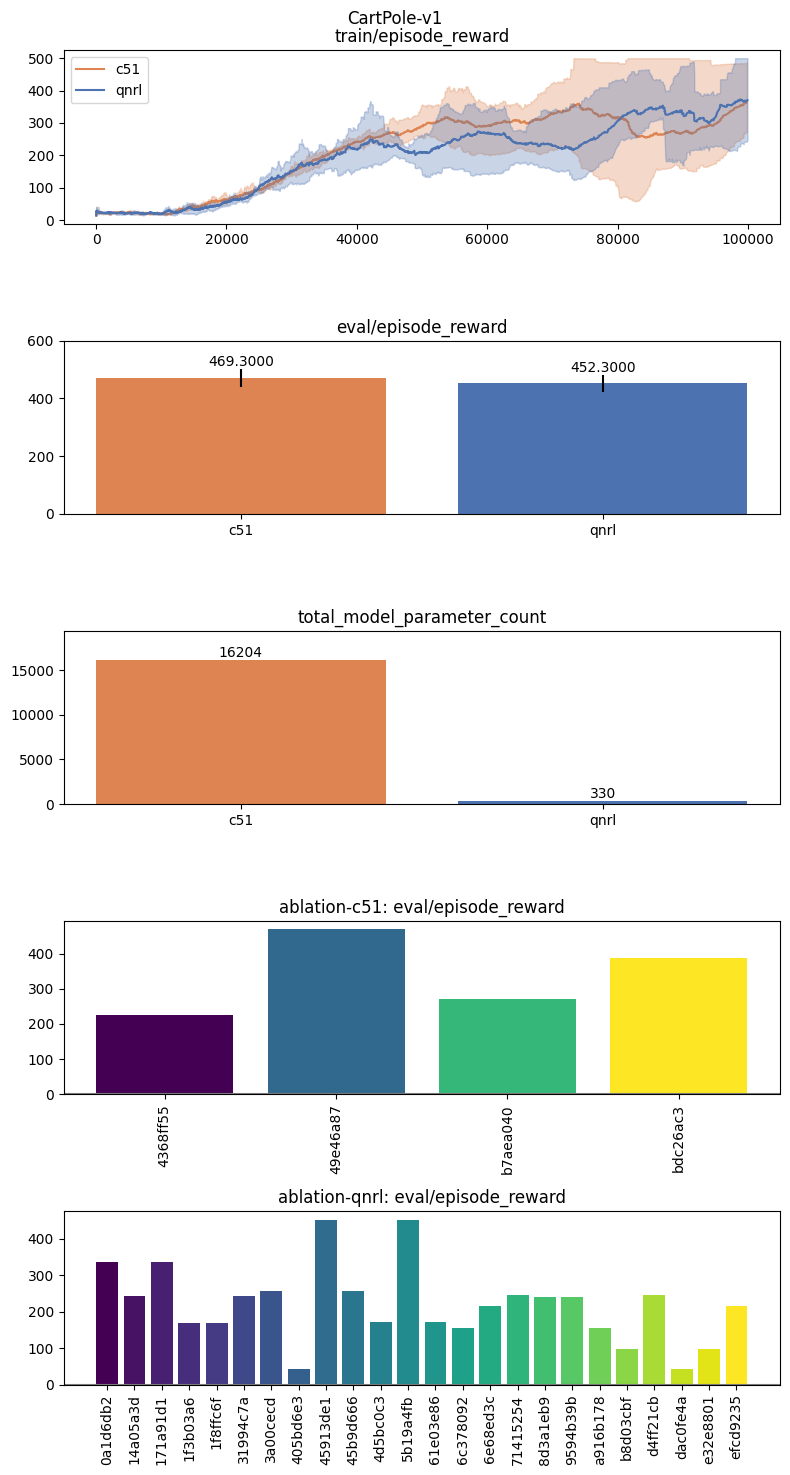

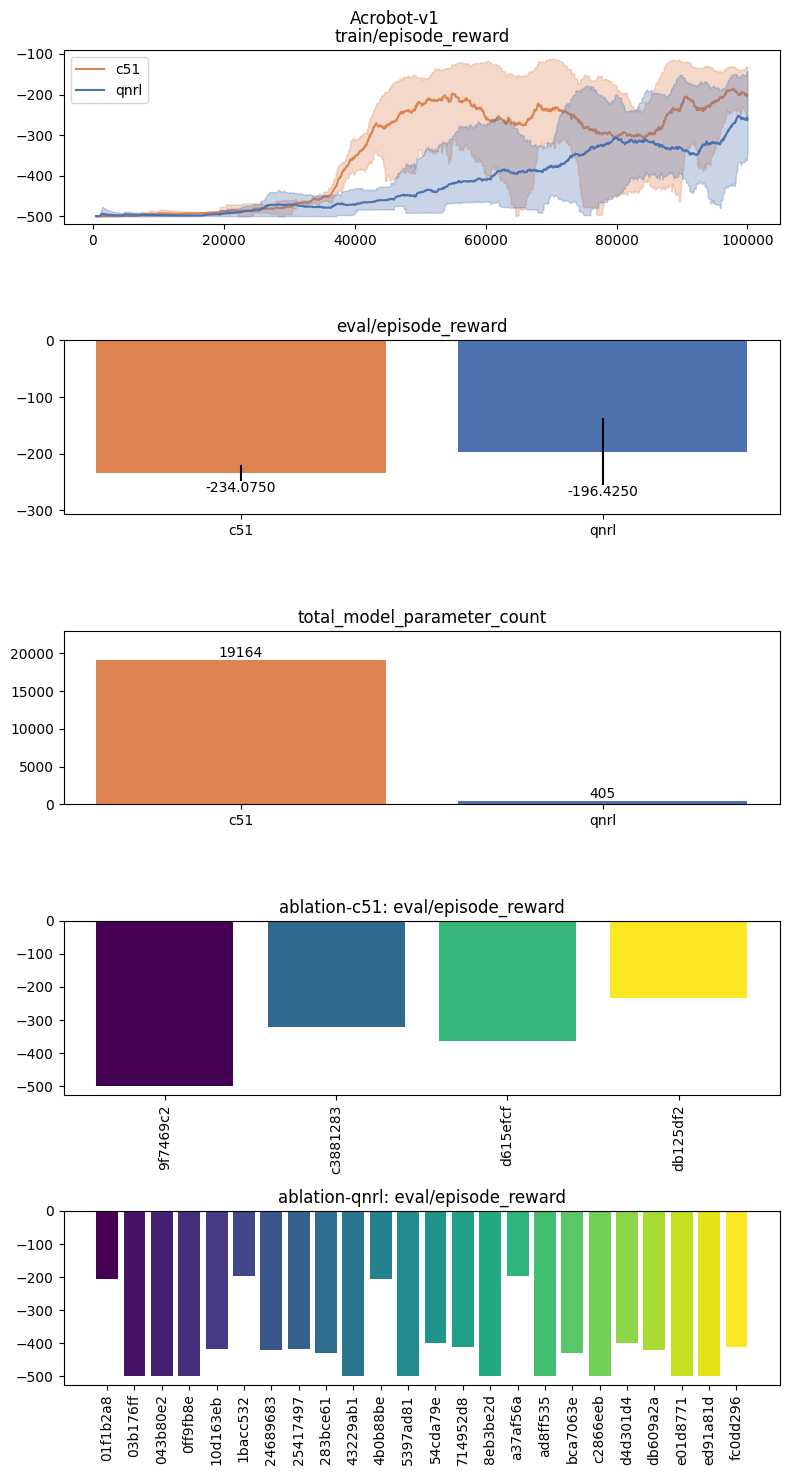

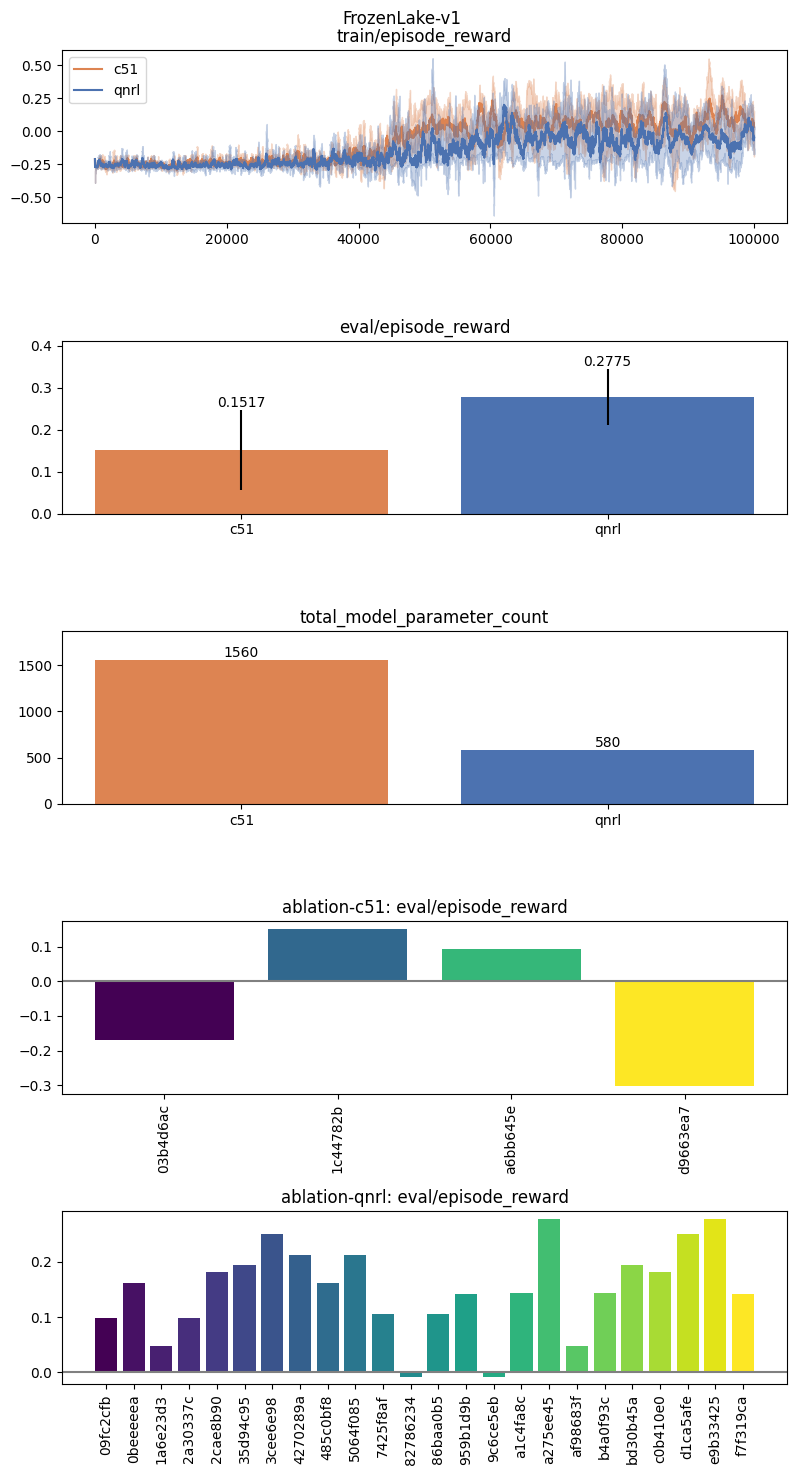

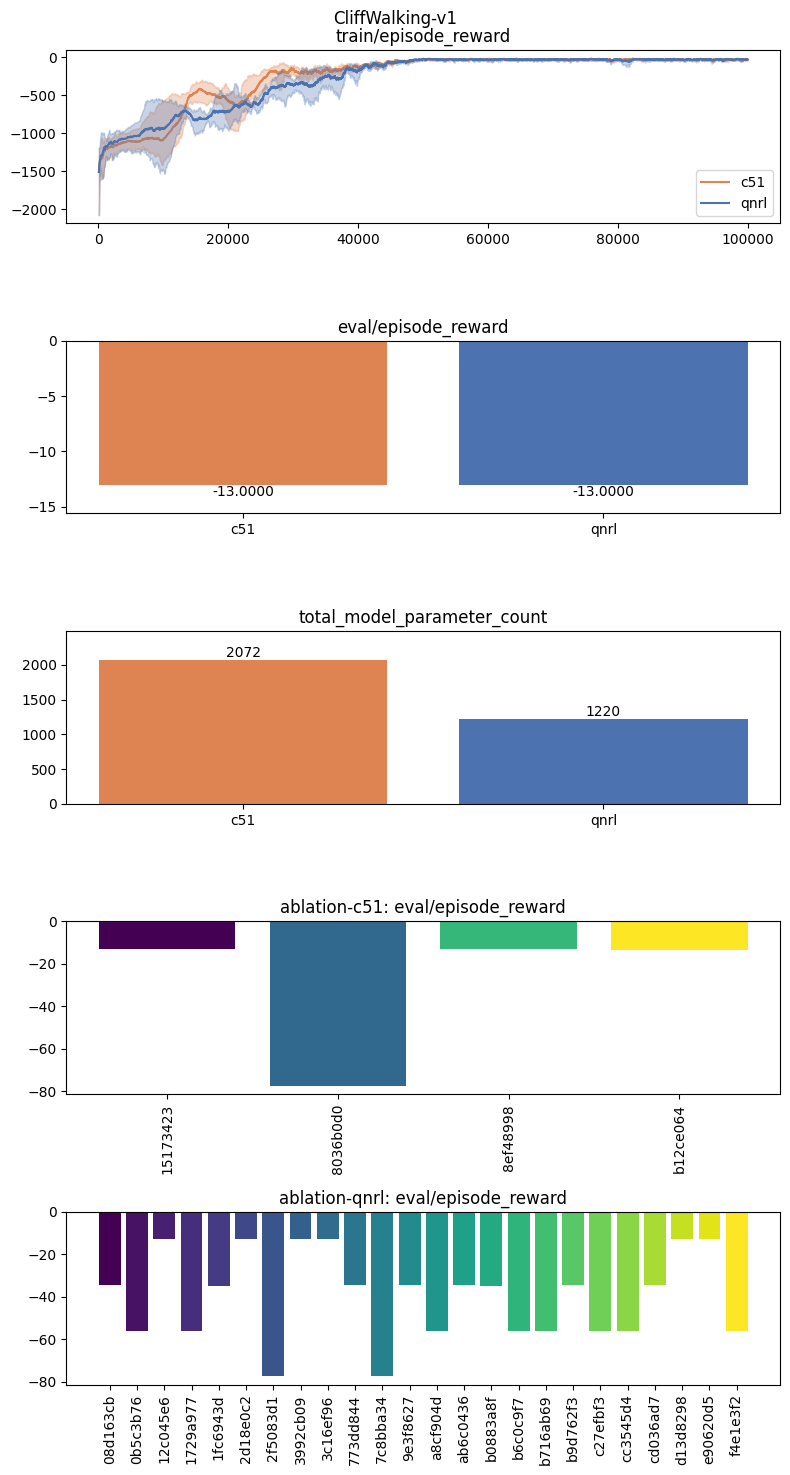

In [39]:
model_keys = ['c51', 'qnrl']
model_colors = {
    'qnrl': [0.2980392156862745,0.4470588235294118,0.6901960784313725],
    'c51': [0.8666666666666667,0.5176470588235295,0.3215686274509804],
}

environment_keys = ['CartPole-v1', 'Acrobot-v1', 'FrozenLake-v1', 'CliffWalking-v1']
# environment_keys = ['CliffWalking-v1', 'FrozenLake-v1']
# environment_keys = ['Acrobot-v1']
# environment_keys = ['CartPole-v1']

figs = []
for env_key in environment_keys:

    figure_meta = {
        # Create plot based on type.
        "type": "mosaic",
        "kwargs": {
            "mosaic": [
                ['train/episode_reward'],
                ['eval/episode_reward'],
                ['eval/total_model_parameter_count'],
                *[
                    [f"ablation-{model_key}"]
                    for i, model_key in enumerate(model_keys)
                ],
            ],
            'figsize': (8,15),
        },
        "title": f"{env_key}",
        
        # Axis configuration for every axis in the figure (list or dictionary of axes).
        "ax": {
            # Axis object.
            # This is what gets plotted, and includes custom plot types.
            'train/episode_reward': {
                'title': f"train/episode_reward",
                'legend': {
                    'loc': 'best',
                    # 'loc': 'lower center',
                    # 'ncol': 4,
                    # 'bbox_to_anchor': (0.5, 1.12),
                },
                "plots": [
                    # # Horizontal line.
                    # {
                    #     "type": "axhline",
                    #     "y": 100,
                    #     "color": "gray",
                    #     "linestyle": "--",
                    # },
                    
                    # Plot within axis.
                    {
                        "type": "line-agg-mean",
                        "label-format": "{key}",
                        'series': [
                            {
                                'label': model_key,
                                'sweep': sweep_name_id[f'{model_key}/{env_key}'], 
                                'runs': best_runs_for_sweep[f'{model_key}/{env_key}'], 
                                'color': model_colors[model_key],
                                'zorder': i,
                                'x': 'train/step',
                                'y': 'train/episode_reward',
                                'window': 100,
                            }
                            for i, model_key in enumerate(model_keys)
                        ],
                    },
                ],
            },
            
            'eval/episode_reward': {
                'title': f"eval/episode_reward",
                # 'legend': {
                #     'loc': 'best',
                #     # 'loc': 'lower center',
                #     # 'ncol': 4,
                #     # 'bbox_to_anchor': (0.5, 1.12),
                # },
                "margins": {
                    "y": 0.2,
                },
                "plots": [
                    {
                        "type": "bar-agg-mean",
                        "bar-orientation": 'v',
                        "bar-label": {
                            'fmt': '{:,.04f}',
                            'label_type': 'edge',
                        },
                        "yerr": "std",
                        "label-format": "{key} ({mean:.04f})",
                        'series': [
                            {
                                'label': model_key,
                                'sweep': sweep_name_id[f'{model_key}/{env_key}'], 
                                'runs': best_runs_for_sweep[f'{model_key}/{env_key}'], 
                                'color': model_colors[model_key],
                                'zorder': i,
                                'x': 'eval/step',
                                'y': 'eval/episode_reward',
                                'window': 10,
                            }
                            for i, model_key in enumerate(model_keys)
                        ],
                    },
                ],
            },
            
            'eval/total_model_parameter_count': {
                'title': f"total_model_parameter_count",
                "margins": {
                    "y": 0.2,
                },
                # 'legend': {
                #     'loc': 'best',
                #     # 'loc': 'lower center',
                #     # 'ncol': 4,
                #     # 'bbox_to_anchor': (0.5, 1.12),
                # },
                "plots": [
                    {
                        "type": "bar-agg-mean",
                        "bar-orientation": 'v',
                        "bar-label": {
                            'fmt': '{:.0f}',
                            'label_type': 'edge',
                        },
                        "label-format": "{key}",
                        'series': [
                            {
                                'label': model_key,
                                'sweep': sweep_name_id[f'{model_key}/{env_key}'], 
                                'runs': best_runs_for_sweep[f'{model_key}/{env_key}'], 
                                'color': model_colors[model_key],
                                'zorder': i,
                                'x': 'eval/step',
                                'y': 'eval/total_model_parameter_count',
                                'window': 10,
                            }
                            for i, model_key in enumerate(model_keys)
                        ],
                    },
                ],
            },
            
            # Show ablation for all models.
            **{
                f"ablation-{model_key}": {
                    'title': f"ablation-{model_key}: eval/episode_reward",
                    # 'legend': {
                    #     # 'loc': 'best',
                    #     # 'loc': 'lower center',
                    #     'loc': 'center',
                    #     'ncol': 4,
                    #     'bbox_to_anchor': (1.12, 1.12),
                    # },
                    'xticks': {
                        'rotation': 90,
                    },
                    # "margins": {
                    #     "y": 0.8,
                    # },
                    'plots': [
                        {
                            "type": "axhline",
                            "y": 0.0,
                            "color": "gray",
                        },
                        {
                            "type": "bar-agg-mean",
                            "bar-orientation": 'v',
                            # "bar-label": {
                            #     'fmt': '{:.04f}',
                            #     'label_type': 'edge',
                            #     'rotation': 90,
                            # },
                            'agg': "mean",
                            "yerr": None,
                            'series': [
                                {
                                    'label': group_id.split('-')[0],
                                    'sweep': sweep_name_id[f'{model_key}/{env_key}'], 
                                    'runs': runs, 
                                    'zorder': i,
                                    'y': 'eval/episode_reward',
                                    'window': 10,
                                }
                                for i, (group_id, runs) in enumerate(sorted(seedgroups_tree[sweep_name_id[f'{model_key}/{env_key}']].items()))
                            ],
                        },
                    ],
                }
                for i, model_key in enumerate(model_keys)
            },
        },
    }

    fig = generate_figure(figure_meta)
    fig.tight_layout()
    # print(fig)
    
    figs.append(fig)

# figs

------

## Ablation: CartPole-v1

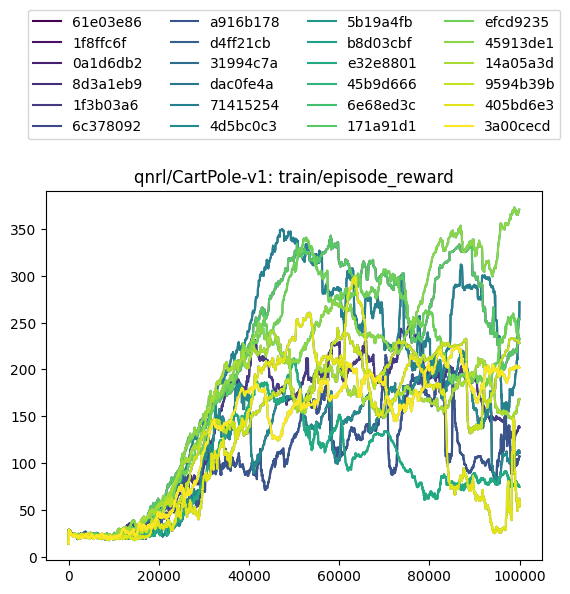

In [211]:
figure_meta = {
    'type': 'line-agg-mean',
    # 'title': "qnrl/CartPole-v1: train/episode_reward",
    'series': [
        {
            'label': group_id.split('-')[0],
            'sweep': sweep_name_id['qnrl/CartPole-v1'], 
            'runs': runs, 
            # 'color': cmap(colors_idx[i]),
            'zorder': 2,
            'x': 'train/step',
            'y': 'train/episode_reward',
            'window': 100,
            'fill_between': None,
            # 'fill_between': {
            #     'alpha': 0.3,
            #     'interpolate': True,
            # },
        }
        for i, (group_id, runs) in enumerate(seedgroups_tree[sweep_name_id['qnrl/CartPole-v1']].items())
    ],
    'ax': {
        'title': "qnrl/CartPole-v1: train/episode_reward",
        'legend': {
            'loc': 'lower center',
            'ncol': 4,
            'bbox_to_anchor': (0.5, 1.12),
        },
    }
    # 'ax': {
    #     'xticks': {
    #         'rotation': 90,
    #     },
    # },
    # 'bar-label': {
    #     'fmt': '{:,.0f}',
    #     'label_type': 'edge',
    # },
}
fig, data = generate_figure_from_meta(figure_meta)